# Week 9 Lab — Stresses that change with time

**HWRS 564a · Fall 2026**

Models we've used so far has been steady state, the answer is what the aquifer
settles down to if the stresses never change. That is a useful question and it is
not the one water managers ask.

They ask things like when does the water table reach the pump intake? How long until
the cone reaches the county line? How much of what we pump this year comes out of
storage rather than out of recharge?

Answering those needs a transient model, which means time steps, storage
properties, and stresses that vary. Additionally we will add one new package, `EVT`, for
evapotranspiration.

## Learning objectives

By the end of this notebook you can:

1. Set up multiple stress periods with `perlen`, `nstp`, and `steady`
2. Explain what `sy` and `ss` are and when each one applies
3. Vary a well's rate between stress periods
4. Read a time series of heads out of the `.hds` file
5. Use the budget to say how much pumped water came out of storage
6. Add `EVT` and explain what the extinction depth does

---

## Part 1 — Setup

In [2]:
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../..")  # course repo root
DATA = ROOT / "data"
MF_EXE = ROOT / "modflow" / "mf2005"
assert MF_EXE.exists(), (
    f"MODFLOW binary not found at {MF_EXE}. Run ./postbuild.sh from a terminal."
)

RUN = ROOT / "_run"
land_surface = np.loadtxt(DATA / "tucson_grid_top.csv", delimiter=",")

NROW, NCOL, DELR = 40, 60, 250.0
AQ_TOP, AQ_BOT = 600.0, 400.0
WELL_ROW, WELL_COL = 20, 30

UA_RED, UA_BLUE, UA_SKY = "#AB0520", "#0C234B", "#81D3EB"
print("ready")

ready


---

## Part 2 — Time in MODFLOW

MODFLOW splits a simulation into **stress periods**, and each stress period into
**time steps**.

- A **stress period** is an interval over which every stress is constant. Change
  the pumping rate and you need a new stress period.
- A **time step** is a solver interval within a stress period. More steps means a
  more accurate transient response and a slower run.

Three arrays in `DIS` control it:

| Argument | Meaning |
|---|---|
| `perlen` | length of each stress period, in the model's time units |
| `nstp` | number of time steps within each stress period |
| `steady` | one flag per period: steady state or transient |

In [3]:
# steady state, then a 30-day period with DAILY steps, then ten annual periods
perlen = [1.0, 30.0] + [365.0] * 10
nstp = [1, 30] + [4] * 10
steady = [True] + [False] * 11
NPER = len(perlen)

total_days = sum(p for p, s in zip(perlen, steady) if not s)
print(f"{NPER} stress periods, {sum(nstp)} time steps")
print(f"transient simulation covers {total_days:,.0f} days = {total_days / 365:.1f} years")

12 stress periods, 71 time steps
transient simulation covers 3,680 days = 10.1 years


> **Why the odd 30-day period with daily steps?** 
> **Why start with a steady-state period?** 

Running one steady-state period first, with no pumping, produces heads that are
already in equilibrium. The stress periods after that is the response to the pumping
you added. 

- `n_transient_periods` — how many periods are transient
- `days_per_annual_step` — length of one time step in the *annual* periods
- `total_output_times` — how many head snapshots a run will produce, if you save
  every time step

In [5]:
n_transient_periods = sum(1 for s in steady if not s)
days_per_annual_step = 365.0 / 4
total_output_times = sum(nstp)

print(f'Number of transient steps: {n_transient_periods}')
print(f'Days per annual step: {days_per_annual_step}')
print(f'Total output timesteps: {total_output_times}')

Number of transient steps: 11
Days per annual step: 91.25
Total output timesteps: 71


---

## Part 3 — Storage: `sy` and `ss`

A steady-state model needs no storage properties — nothing is changing. A
transient one does, because water has to come from somewhere while heads fall.

| Property | Symbol | Applies when | Typical value | Units |
|---|---|---|---|---|
| **Specific yield** | `sy` | unconfined — pores actually drain | 0.05 – 0.30 | dimensionless |
| **Specific storage** | `ss` | confined — water expands, matrix compresses | 1e-6 – 1e-4 | 1/m |

Note they differ by three to four orders of magnitude. A confined aquifer
releases almost no water per metre of head decline, which is why confined
drawdown propagates so fast and so far.

In [6]:
SY, SS = 0.15, 1e-5
cell_area = DELR * DELR
thickness = AQ_TOP - AQ_BOT

unconfined_release = SY * cell_area * 1.0
confined_release = SS * cell_area * thickness * 1.0

print(f"water released by 1 m of decline in one {DELR:.0f} m cell:")
print(f"  unconfined (sy = {SY})      {unconfined_release:10,.1f} m3")
print(f"  confined   (ss = {SS:.0e})  {confined_release:10,.1f} m3")
print(f"  ratio                      {unconfined_release / confined_release:10,.0f}x")

water released by 1 m of decline in one 250 m cell:
  unconfined (sy = 0.15)         9,375.0 m3
  confined   (ss = 1e-05)       125.0 m3
  ratio                              75x


### The standard confined example we've been using

Our model is confined (`laytyp=0`), so `ss` is what governs it. Work out how much
water the whole aquifer can supply from storage before the answer has to come
from somewhere else.

- `storage_per_metre` — water released by 1 m of head decline across all 2,400 cells
- `days_of_pumping` — how many days of 20,000 m³/d that would cover

In [8]:
PUMP_RATE = 20000.0     # m3/d

storage_per_metre = SS * cell_area * thickness * NROW * NCOL
days_of_pumping = storage_per_metre / PUMP_RATE

days_of_pumping

15.0

About 2 weeks is a good first upper bound. Even if the entire aquifer dropped a
metre, storage could only cover that much time of this well. That is why a confined
aquifer reaches something close to steady state so quickly: there is very little
in storage, so the cone has to keep expanding until it intercepts enough recharge
or boundary flow to balance the well.  Run the same numbers unconfined and storage per metre goes up by a factor of
`sy / (ss * b)` = `0.15 / (1e-5 x 200)` = 75. That is over three years of
pumping available from storage rather than two weeks.

---

## Part 4 — A transient run

The well switches on at the start of year 1 and stays on.

In [9]:
WS = RUN / "week09_transient"
WS.mkdir(parents=True, exist_ok=True)

mf = flopy.modflow.Modflow("trans", model_ws=str(WS), exe_name=str(MF_EXE))
flopy.modflow.ModflowDis(
    mf, 1, NROW, NCOL, delr=DELR, delc=DELR,
    top=AQ_TOP, botm=AQ_BOT,
    nper=NPER, perlen=perlen, nstp=nstp, steady=steady,
)

ibound = np.ones((1, NROW, NCOL), dtype=int)
ibound[:, :, 0] = -1
ibound[:, :, -1] = -1
strt = np.full((1, NROW, NCOL), 660.0)
strt[:, :, 0] = 620.0
strt[:, :, -1] = 700.0
flopy.modflow.ModflowBas(mf, ibound=ibound, strt=strt)

# storage properties matter now
flopy.modflow.ModflowLpf(mf, hk=12.0, laytyp=0, sy=SY, ss=SS, ipakcb=53)

# stress period 0 is the no-pumping steady state; the well runs from period 1
wel_spd = {}
wel_spd[0] = [[0, WELL_ROW, WELL_COL, 0.0]]
wel_spd[1] = [[0, WELL_ROW, WELL_COL, -PUMP_RATE]]

flopy.modflow.ModflowWel(mf, stress_period_data=wel_spd, ipakcb=53)
flopy.modflow.ModflowRch(mf, rech={p: 1.2e-4 for p in range(NPER)}, ipakcb=53)

flopy.modflow.ModflowPcg(mf)
flopy.modflow.ModflowOc(
    mf,
    stress_period_data={(p, s): ["save head", "save budget"]
                        for p in range(NPER) for s in range(nstp[p])},
)

mf.write_input()
success, buff = mf.run_model(silent=True, report=True)
assert success, "MODFLOW did not converge:\n" + "\n".join(buff[-20:])
print("converged")

converged


Note the `stress_period_data` dictionary contains one entry per stress period, keyed
by period number. That is how any stress varies in time, the well package, the
recharge package, others in the `flopy` world work in a similar structure.

# Pulling the heads
Pull the head history at the wellfield out of the file.

- `well_history` — head in the well cell at every output time, as a 1D array
- `years` — the output times converted to years since pumping began
  (the steady-state period occupies day 0–1, so subtract 1 day then divide by 365)
- `total_drawdown` — head at the first output time minus head at the last

In [10]:
hds = flopy.utils.HeadFile(str(WS / "trans.hds"))
times = np.array(hds.get_times())

print(f"{len(times)} output times, from {times[0]:.1f} to {times[-1]:,.1f} days")
print(f"first few: {np.round(times[:5], 1)}")


71 output times, from 1.0 to 3,681.0 days
first few: [1. 2. 3. 4. 5.]


In [14]:
hds.get_data(totim=times[1]).shape

(1, 40, 60)

In [15]:
times

array([1.00000e+00, 2.00000e+00, 3.00000e+00, 4.00000e+00, 5.00000e+00,
       6.00000e+00, 7.00000e+00, 8.00000e+00, 9.00000e+00, 1.00000e+01,
       1.10000e+01, 1.20000e+01, 1.30000e+01, 1.40000e+01, 1.50000e+01,
       1.60000e+01, 1.70000e+01, 1.80000e+01, 1.90000e+01, 2.00000e+01,
       2.10000e+01, 2.20000e+01, 2.30000e+01, 2.40000e+01, 2.50000e+01,
       2.60000e+01, 2.70000e+01, 2.80000e+01, 2.90000e+01, 3.00000e+01,
       3.10000e+01, 1.22250e+02, 2.13500e+02, 3.04750e+02, 3.96000e+02,
       4.87250e+02, 5.78500e+02, 6.69750e+02, 7.61000e+02, 8.52250e+02,
       9.43500e+02, 1.03475e+03, 1.12600e+03, 1.21725e+03, 1.30850e+03,
       1.39975e+03, 1.49100e+03, 1.58225e+03, 1.67350e+03, 1.76475e+03,
       1.85600e+03, 1.94725e+03, 2.03850e+03, 2.12975e+03, 2.22100e+03,
       2.31225e+03, 2.40350e+03, 2.49475e+03, 2.58600e+03, 2.67725e+03,
       2.76850e+03, 2.85975e+03, 2.95100e+03, 3.04225e+03, 3.13350e+03,
       3.22475e+03, 3.31600e+03, 3.40725e+03, 3.49850e+03, 3.589

In [19]:
data = []
for t in times:
    data.append(
        hds.get_data(totim=t)[0, WELL_ROW, WELL_COL]
    )
print(WELL_COL, WELL_ROW)
data = np.array(data)
data.shape

30 20


(71,)

In [22]:
well_history = np.array([
    hds.get_data(totim=t)[0, WELL_ROW+10, WELL_COL+10] for t in times
])
years = (times - 1.0) / 365.0
total_drawdown = well_history[0] - well_history[-1]

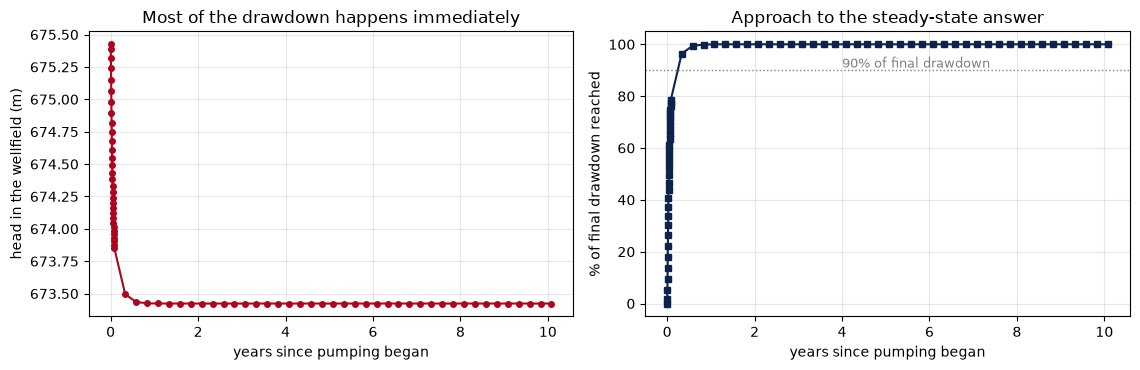

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))

axes[0].plot(years, well_history, "o-", color=UA_RED, ms=4)
axes[0].set_xlabel("years since pumping began")
axes[0].set_ylabel("head in the wellfield (m)")
axes[0].set_title("Most of the drawdown happens immediately")
axes[0].grid(alpha=0.3)

# how much of the final drawdown is reached by each time
fraction = (well_history[0] - well_history) / total_drawdown * 100
axes[1].plot(years, fraction, "s-", color=UA_BLUE, ms=4)
axes[1].axhline(90, color="grey", ls=":", lw=1)
axes[1].text(4, 91, "90% of final drawdown", fontsize=9, color="grey")
axes[1].set_xlabel("years since pumping began")
axes[1].set_ylabel("% of final drawdown reached")
axes[1].set_title("Approach to the steady-state answer")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# How much of the drawdown happens immediately?

The right panel says the model reaches most of its final drawdown quickly. Here we put a
number on it by calculating:

- `pct_after_one_year` — percentage of the final drawdown reached after 1 year
- `years_to_90pct` — the first time in `years` at which 90% is reached

`np.argmax` on a boolean array gives the index of the first `True`.

In [24]:
pct_after_one_year = float(np.interp(1.0, years, fraction))
years_to_90pct = float(years[np.argmax(fraction >= 90)])
years_to_90pct

0.3321917951107025

Confined aquifers are usually nearly at steady state within a year or two. So for
this system, the steady-state model from Week 7 was answering a question about
the near future, not the distant one which is also worth knowing.

Try an unconfined aquifer with `sy = 0.15`. There the
approach is slow enough that a steady-state model describes a condition on a much longer timescale.

---

## Part 5 — Where transient water comes from

In a steady-state model the budget balances recharge against pumping. In a
transient one there is a third source, the storage

In [27]:
def budget_by_period(list_path):
    """Storage, recharge, wells and constant-head terms for each budget block."""
    lines = Path(list_path).read_text().splitlines()
    starts = [i for i, l in enumerate(lines) if "VOLUMETRIC BUDGET" in l]

    records = []
    for s in starts:
        block = lines[s:s + 30]
        half, terms = "in", {}
        for line in block:
            t = line.strip()
            if t.startswith("OUT:"):
                half = "out"
            if "=" not in t or t.startswith(("TOTAL", "IN - OUT", "PERCENT")):
                continue
            name = t.split("=")[0].strip()
            terms.setdefault(name, {})[half] = float(t.split()[-1])
        records.append(terms)
    return records


blocks = budget_by_period(WS / "trans.list")
print(f"{len(blocks)} budget blocks written")

final = blocks[-1]
for name, v in final.items():
    print(f"  {name:16s} in {v.get('in', 0):11,.1f}   out {v.get('out', 0):11,.1f}")

12 budget blocks written
  STORAGE          in         0.0   out         0.0
  CONSTANT HEAD    in   131,639.0   out   129,039.0
  WELLS            in         0.0   out    20,000.0
  RECHARGE         in    17,400.0   out         0.0


MODFLOW writes one budget block per stress period, at the end of it, not one
per time step. So `blocks[1]` is the end of the 30-day period and `blocks[-1]` is
the end of year 10.

### Checking the change in storage

Compare the end of the first month of pumping with the end of year ten, and show
where the water came from in each.

- `storage_early` — net storage contribution in `blocks[1]` (in minus out)
- `storage_late` — the same for `blocks[-1]`
- `storage_share_early` — storage as a percentage of the pumping rate, early

In [28]:
storage_early = blocks[1]["STORAGE"].get("in", 0.0) - blocks[1]["STORAGE"].get("out", 0.0)
storage_late = blocks[-1]["STORAGE"].get("in", 0.0) - blocks[-1]["STORAGE"].get("out", 0.0)
storage_share_early = 100 * storage_early / PUMP_RATE

The source of pumped water also changes over time, and is a very 
policy-relevant output.

After one month of pumping, about a quarter of the well's yield is water taken
out of storage, that is, a one-off withdrawal from the aquifer's stock rather than a renewable
supply. By year ten storage contributes essentially nothing, and the entire yield
is "captured": recharge that would have gone somewhere else, or flow diverted
from the boundaries. The distinction between *depletion* versus *capture* is a key component
of safe-yield regulation.

---

## Part 6 — Evapotranspiration

Where the water table is shallow, plants and soil reach it. `EVT` removes water
at a rate that depends on how deep the water table is. Remember, MODFLOW only 
represents fully-saturated flow so this is why it must be added separately.
Do you think this is representative of the Tucson basin?

Three arguments:

| Argument | Meaning |
|---|---|
| `surf` | the elevation at which ET is at its maximum rate |
| `evtr` | that maximum rate, as a flux (m/d) |
| `exdp` | **extinction depth** — how far below `surf` ET reaches zero |

Between `surf` and `surf - exdp`, MODFLOW interpolates linearly. Below it, ET
stops.

In [36]:
WS_ET = RUN / "week09_et"
WS_ET.mkdir(parents=True, exist_ok=True)

# A shallow-water-table version, so ET has something to work on
mf_et = flopy.modflow.Modflow("et", model_ws=str(WS_ET), exe_name=str(MF_EXE))
flopy.modflow.ModflowDis(mf_et, 1, NROW, NCOL, delr=DELR, delc=DELR,
                         top=700.0, botm=400.0, nper=1, steady=True)
ib = np.ones((1, NROW, NCOL), dtype=int)
ib[:, :, 0] = -1
ib[:, :, -1] = -1
strt_et = np.full((1, NROW, NCOL), 690.0)
strt_et[:, :, 0] = 685.0
strt_et[:, :, -1] = 695.0
flopy.modflow.ModflowBas(mf_et, ibound=ib, strt=strt_et)
flopy.modflow.ModflowLpf(mf_et, hk=12.0, laytyp=0, ipakcb=53)
flopy.modflow.ModflowRch(mf_et, rech=6.0e-4, ipakcb=53)

ET_SURF = 700.0        # ET is at its maximum when head reaches 700 m
ET_RATE = 3.0e-3       # m/d, about 1100 mm/yr — riparian vegetation
ET_EXDP = 200.0          # m, extinction depth

flopy.modflow.ModflowEvt(mf_et, surf=ET_SURF, evtr=ET_RATE, exdp=ET_EXDP,
                         nevtop=1, ipakcb=53)
flopy.modflow.ModflowPcg(mf_et)
flopy.modflow.ModflowOc(mf_et, stress_period_data={(0, 0): ["save head", "save budget"]})
mf_et.write_input()
ok_et, buff_et = mf_et.run_model(silent=True, report=True)
assert ok_et, "\n".join(buff_et[-15:])

head_et = flopy.utils.HeadFile(str(WS_ET / "et.hds")).get_data()
print(f"head {head_et.min():.2f} to {head_et.max():.2f} m")
print(f"depth below the ET surface: {ET_SURF - head_et.max():.2f} to "
      f"{ET_SURF - head_et.min():.2f} m")

head 674.09 to 695.00 m
depth below the ET surface: 5.00 to 25.91 m


### How much water could come from ET with this setup?

- `max_possible_et` — `ET_RATE` times the area of all active cells
- `actual_et` — the `ET` term from the budget (out side)
- `et_fraction` — actual as a percentage of maximum

In [37]:
et_terms = budget_by_period(WS_ET / "et.list")[-1]
print("budget terms:", sorted(et_terms))

max_possible_et = ET_RATE * int((ib > 0).sum()) * DELR * DELR
actual_et = et_terms["ET"]["out"]
et_fraction = 100 * actual_et / max_possible_et
print(max_possible_et, actual_et, et_fraction)


budget terms: ['CONSTANT HEAD', 'ET', 'RECHARGE', 'STORAGE']
435000.0 390268.2188 89.71683190804596


ET comes in below the maximum because the water table sits partway down the
extinction interval, so MODFLOW applies a scaled rate, cell by cell.
Why the extinction depth matters quite a bit by creating a feedback:
pumping lowers the water table, which reduces ET, which leaves more water in the
aquifer. So a fraction of what a well produces is not new water, it is
water that would otherwise have been transpired by the vegetation along the
river.
This is a behavior/balance we see behind riparian habitat
loss along the Santa Cruz river, and a model without an `EVT` package cannot represent
it at all.

---

## Before you leave

1. *Kernel → Restart Kernel and Run All Cells*
2. Fix anything that breaks
3. Save

## What's due

- Nothing for now, we will revisit on Thursday due to jury duty uncertainty.

## Next week

Layered models, rivers, and loading a model somebody else built, followed by
a guided Thursday model-comparison workshop.

## Stuck?

- `stress_period_data` must have an entry for **every** stress period, or FloPy
  reuses the previous one silently. Build it with a dict comprehension.
- A transient model that runs but shows no change usually has `steady=True` in
  every period — check the `DIS` flags.
- `KeyError` on a budget term means the package didn't write to the budget file:
  add `ipakcb=53`.
- If the heads barely move over ten years, check `ss` — a value of 1e-7 makes the
  aquifer respond almost instantly.
- Office hours: Tuesdays 1:00–2:00pm, Harshbarger 232.